# Testing Revised Point Spread Functions for AIA

Revised functions downloaded from `doi.org/10.7910/DVN/DYT4ZL`. 

In [1]:
import os
from pathlib import Path

import aiapy.psf
import astropy.units as u
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np
import sunpy.map
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.nddata import CCDData
from matplotlib import colors

from aia_psf_deconvolution.physics import deconvolve_bid
from aia_psf_deconvolution.physics.hofmeister_bid import convolve_image

/opt/miniconda3/envs/sdac/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Look at the Downloaded AIA PSF Files for Hofmeister et al. (2025)
data_dir = Path(os.environ.get("DATA_DIR", "./data"))
psf_dir = data_dir / "psfs"
hofmeister_psf_dir = psf_dir / "hofmeister_2025"

# The PSF Functions are stored in FITS Files
hofmeister_psf_files = list(hofmeister_psf_dir.glob("*.fits"))
[file.name for file in hofmeister_psf_files]

['psf_aia_131.fits',
 'psf_aia_193.fits',
 'psf_aia_171.fits',
 'psf_aia_335.fits',
 'psf_aia_211.fits',
 'psf_aia_94.fits',
 'psf_aia_304.fits']

In [3]:
hdul = fits.open(hofmeister_psf_files[0])
hdul.info()

Filename: /Users/arobbert/__SOC_CODE__/SDAC/data/psfs/hofmeister_2025/psf_aia_131.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      18   (8192, 8192)   float64   


In [4]:
# You can get these from AIAPy, example in `notebooks/grigis_2012_psf_testing.ipynb`
grigis_psf_dir = psf_dir / "grigis_2012"
# The PSF Functions are stored in Numpy Files
grigis_psf_files = list(grigis_psf_dir.glob("*.npy"))
[file.name for file in grigis_psf_files]

['psf_304.0.npy',
 'psf_94.0.npy',
 'psf_131.0.npy',
 'psf_335.0.npy',
 'psf_193.0.npy',
 'psf_171.0.npy',
 'psf_211.0.npy']

In [5]:
assert len(hofmeister_psf_files) == len(grigis_psf_files), (
    "The number of PSF files for Hofmeister et al. (2025) and Grigis et al. (2012) do not match."
)

In [6]:
# Hofmeister pattern: `psf_aia_<wavelength>.fits`
# Load the PSF Files for Each Wavelength
# Dict[wavelength, PSF]
hofmeisters = {}
for psf_file in hofmeister_psf_files:
    wavelength = int(psf_file.stem.split("_")[-1])
    psf = CCDData.read(psf_file)
    hofmeisters[wavelength] = psf
for wavelength, psf in hofmeisters.items():
    print(
        f"Wavelength: {wavelength} Å, PSF shape: {psf.data.shape}, PSF sum: {np.sum(psf.data)}"
    )

Wavelength: 131 Å, PSF shape: (8192, 8192), PSF sum: 0.9999999999999973
Wavelength: 193 Å, PSF shape: (8192, 8192), PSF sum: 0.9999999999999983
Wavelength: 171 Å, PSF shape: (8192, 8192), PSF sum: 0.9999999999999996
Wavelength: 335 Å, PSF shape: (8192, 8192), PSF sum: 0.9999999999999972
Wavelength: 211 Å, PSF shape: (8192, 8192), PSF sum: 0.9999999999999989
Wavelength: 94 Å, PSF shape: (8192, 8192), PSF sum: 1.0000000000000007
Wavelength: 304 Å, PSF shape: (8192, 8192), PSF sum: 0.9999999999999974


In [7]:
# Grigis pattern: psf_<wavelength>.npy
# Load the PSF Files for Each Wavelength
# Dict[wavelength, PSF]
grigises = {}
for psf_file in grigis_psf_files:
    wavelength = int(float(psf_file.stem.split("_")[-1]))
    psf = np.load(psf_file)
    grigises[wavelength] = psf
for wavelength, psf in grigises.items():
    print(f"Wavelength: {wavelength} Å, PSF shape: {psf.shape}, PSF sum: {np.sum(psf)}")

Wavelength: 304 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000003968
Wavelength: 94 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000004148
Wavelength: 131 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000004097
Wavelength: 335 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000003946
Wavelength: 193 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000004086
Wavelength: 171 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000004068
Wavelength: 211 Å, PSF shape: (4096, 4096), PSF sum: 1.0000000000004052


Text(0.5, 0.995, 'PSF Comparison: Hofmeister (2025) vs Grigis (2012) - Full Resolution')

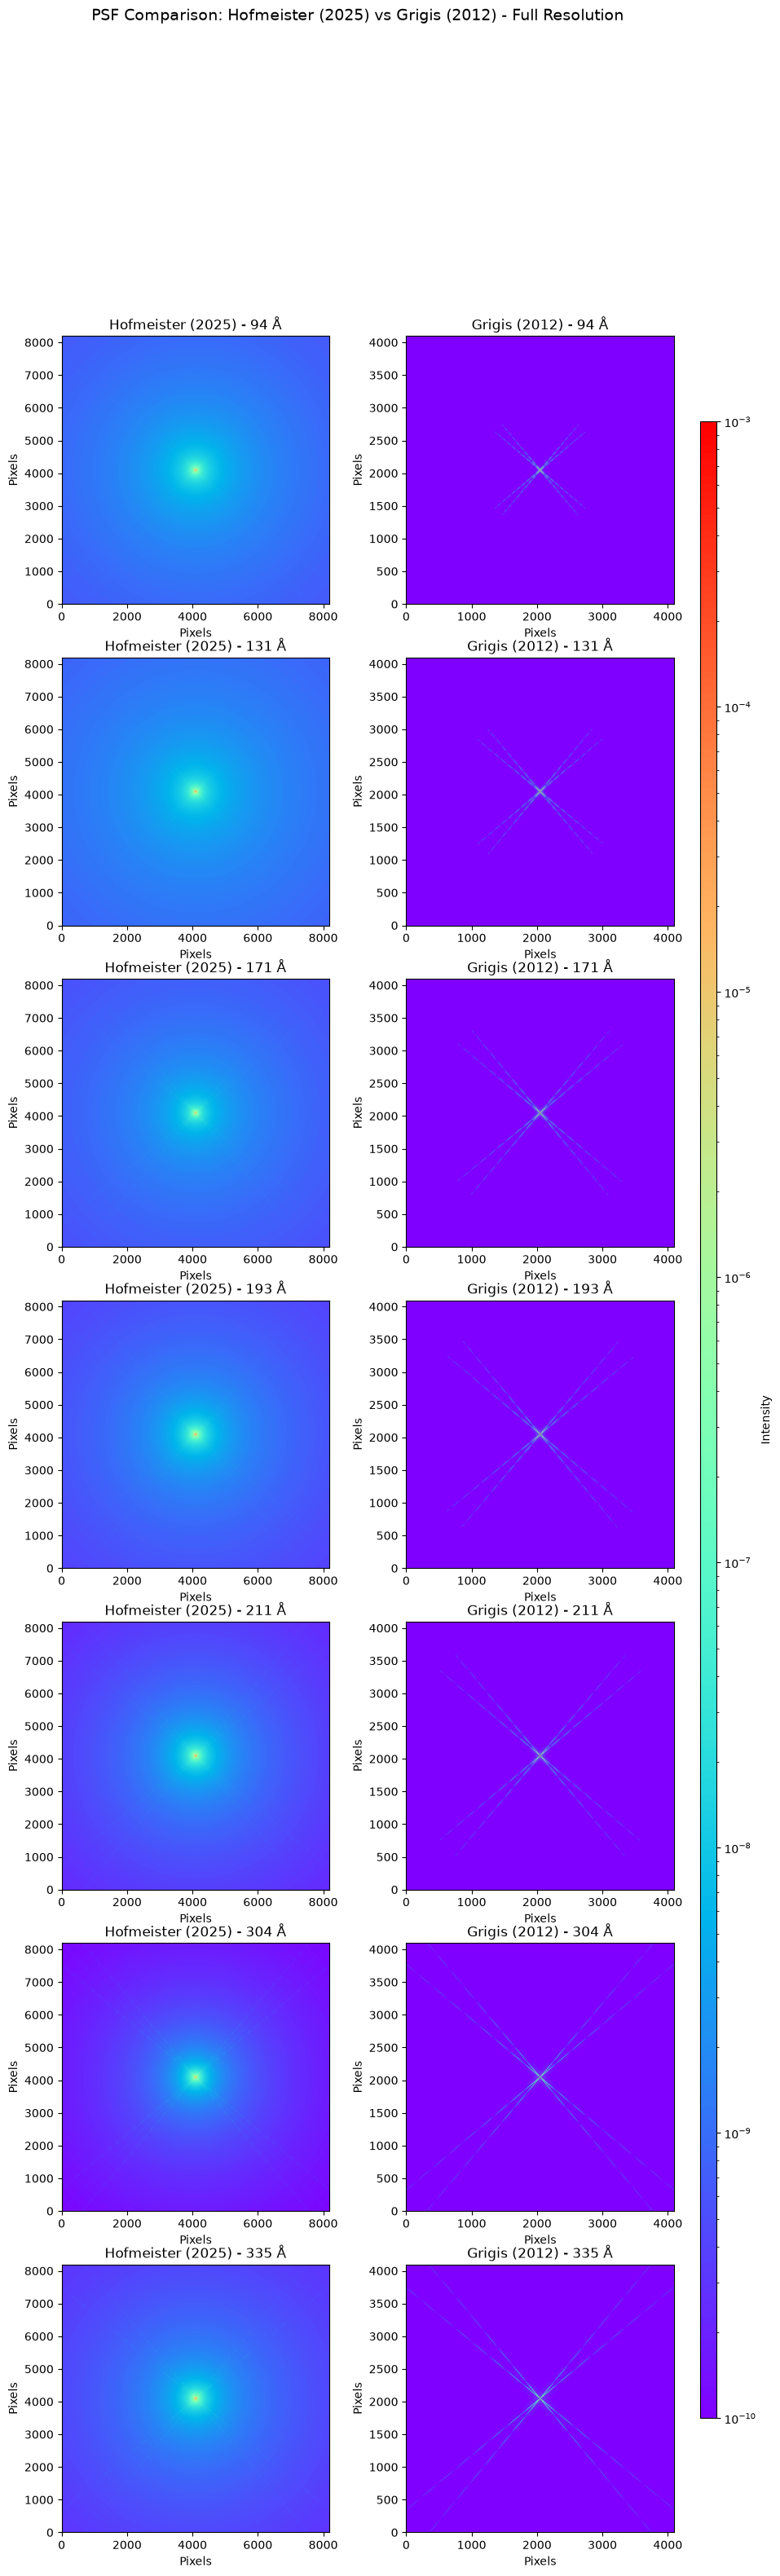

In [8]:
# Full Resolution: Compare Hofmeister vs Grigis PSF side-by-side for each wavelength
n_wavelengths = len(hofmeisters)
n_cols = 2  # Hofmeister and Grigis side by side
n_rows = n_wavelengths

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 5 * n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)

im_list = []
wavelengths = sorted(hofmeisters.keys())

for row, wavelength in enumerate(wavelengths):
    # Hofmeister (left column)
    hofmeister_psf = hofmeisters[wavelength].data
    im_h = axes[row, 0].imshow(
        hofmeister_psf,
        norm=colors.LogNorm(vmin=1e-10, vmax=1e-3),
        origin="lower",
        cmap="rainbow",
    )
    axes[row, 0].set_title(f"Hofmeister (2025) - {wavelength} Å")
    axes[row, 0].set_xlabel("Pixels")
    axes[row, 0].set_ylabel("Pixels")
    im_list.append(im_h)

    # Grigis (right column)
    grigis_psf = grigises[wavelength]
    im_g = axes[row, 1].imshow(
        grigis_psf,
        norm=colors.LogNorm(vmin=1e-10, vmax=1e-3),
        origin="lower",
        cmap="rainbow",
    )
    axes[row, 1].set_title(f"Grigis (2012) - {wavelength} Å")
    axes[row, 1].set_xlabel("Pixels")
    axes[row, 1].set_ylabel("Pixels")
    im_list.append(im_g)

# Add a single colorbar for all subplots (note: they have different ranges per-PSF, so this is illustrative only)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(im_list[0], cax=cbar_ax, label="Intensity")


fig.subplots_adjust(right=0.9)
plt.suptitle(
    "PSF Comparison: Hofmeister (2025) vs Grigis (2012) - Full Resolution",
    fontsize=14,
    y=0.995,
)

Text(0.5, 0.995, 'PSF Comparison: Hofmeister (2025) vs Grigis (2012) - Center 500×500 Crop')

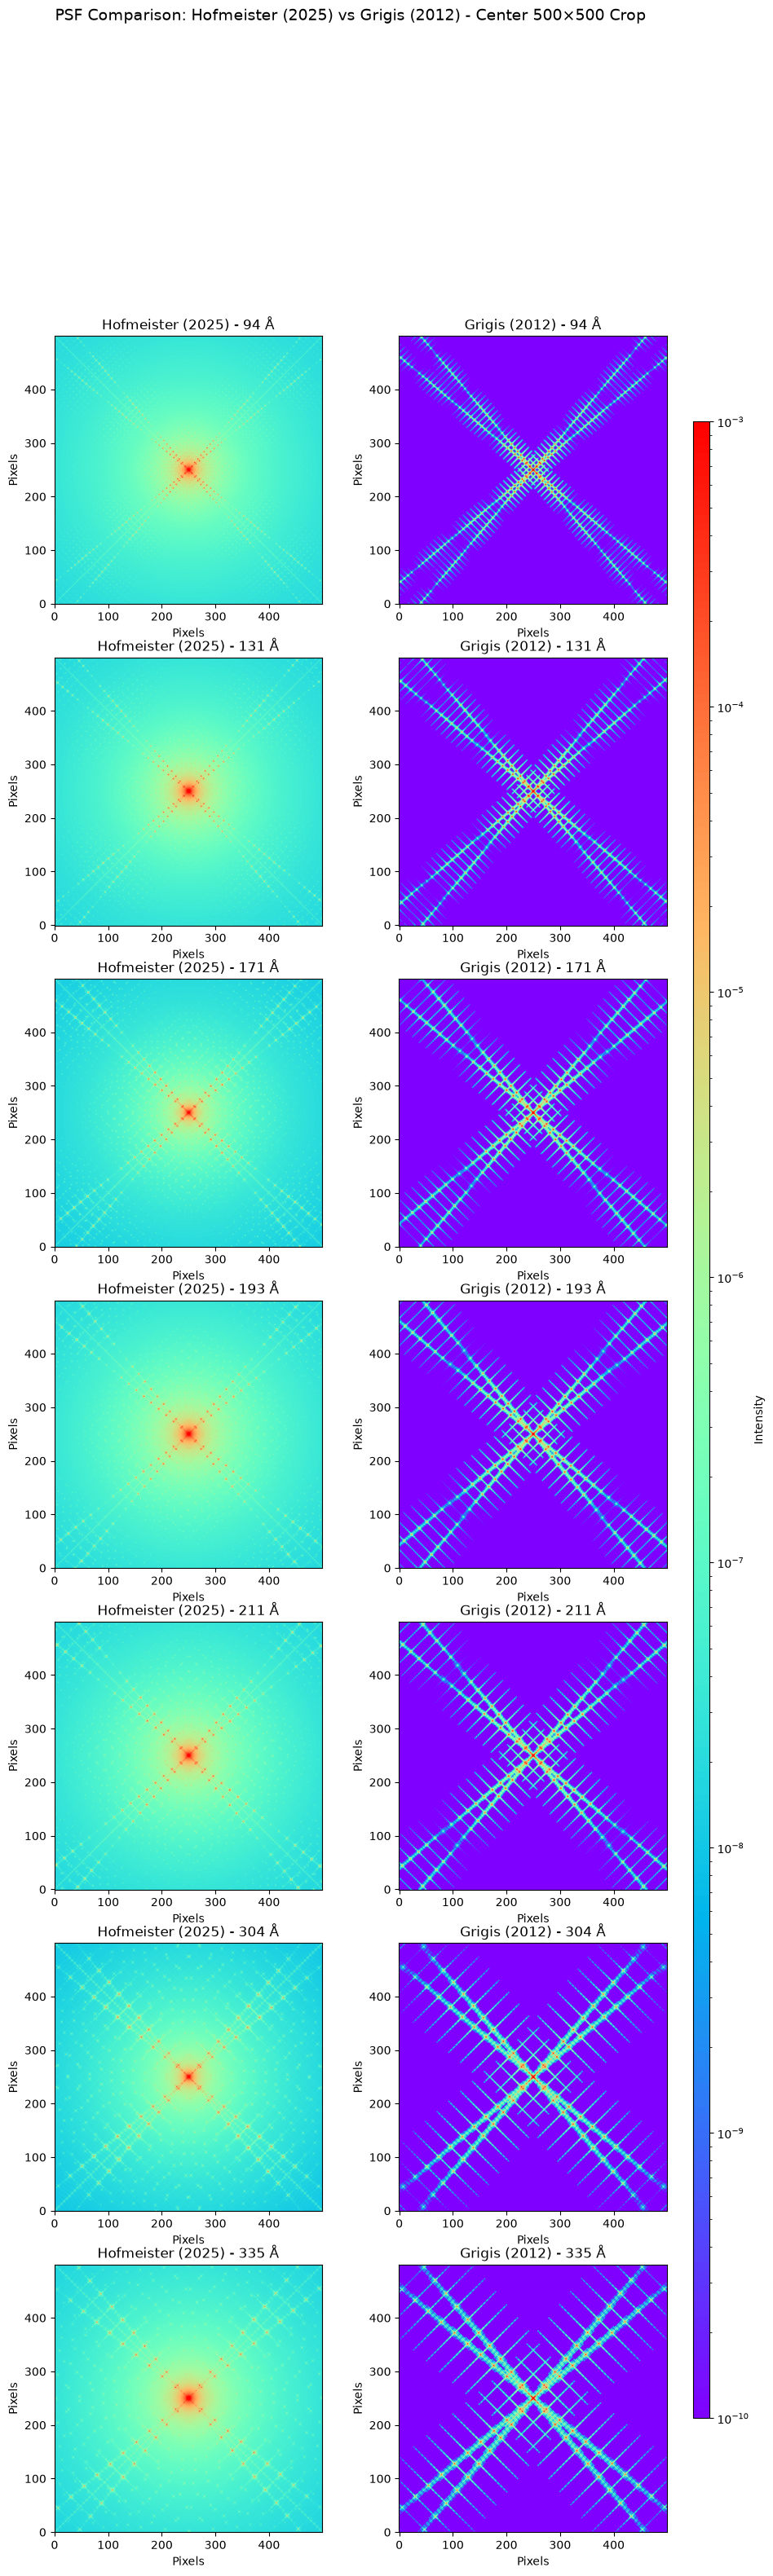

In [9]:
# 500px FOV Crop: Compare Hofmeister vs Grigis PSF side-by-side for each wavelength
n_wavelengths = len(hofmeisters)
n_cols = 2  # Hofmeister and Grigis side by side
n_rows = n_wavelengths
fov = 500

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 5 * n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)

im_list = []
wavelengths = sorted(hofmeisters.keys())

for row, wavelength in enumerate(wavelengths):
    # Hofmeister (left column)
    hofmeister_psf = hofmeisters[wavelength].data
    h_lc_x, h_lc_y = (
        hofmeister_psf.shape[0] // 2 - fov // 2,
        hofmeister_psf.shape[1] // 2 - fov // 2,
    )
    hofmeister_crop = hofmeister_psf[h_lc_x : h_lc_x + fov, h_lc_y : h_lc_y + fov]

    im_h = axes[row, 0].imshow(
        hofmeister_crop,
        norm=colors.LogNorm(vmin=1e-10, vmax=1e-3),
        origin="lower",
        cmap="rainbow",
    )
    axes[row, 0].set_title(f"Hofmeister (2025) - {wavelength} Å")
    axes[row, 0].set_xlabel("Pixels")
    axes[row, 0].set_ylabel("Pixels")
    im_list.append(im_h)

    # Grigis (right column)
    grigis_psf = grigises[wavelength]
    g_lc_x, g_lc_y = (
        grigis_psf.shape[0] // 2 - fov // 2,
        grigis_psf.shape[1] // 2 - fov // 2,
    )
    grigis_crop = grigis_psf[g_lc_x : g_lc_x + fov, g_lc_y : g_lc_y + fov]

    im_g = axes[row, 1].imshow(
        grigis_crop,
        norm=colors.LogNorm(vmin=1e-10, vmax=1e-3),
        origin="lower",
        cmap="rainbow",
    )
    axes[row, 1].set_title(f"Grigis (2012) - {wavelength} Å")
    axes[row, 1].set_xlabel("Pixels")
    axes[row, 1].set_ylabel("Pixels")
    im_list.append(im_g)

# Add a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(im_list[0], cax=cbar_ax, label="Intensity")


fig.subplots_adjust(right=0.9)
plt.suptitle(
    f"PSF Comparison: Hofmeister (2025) vs Grigis (2012) - Center {fov}×{fov} Crop",
    fontsize=14,
    y=0.995,
)

In [10]:
# Load some sample AIA Data to test the two PSF Functions
test_file_path = (
    data_dir / "test_files" / "aia.lev1.171A_2017_09_10T20_00_09.35Z.image_lev1.fits"
)
hdul = fits.open(test_file_path)
hdul.info()

Filename: /Users/arobbert/__SOC_CODE__/SDAC/data/test_files/aia.lev1.171A_2017_09_10T20_00_09.35Z.image_lev1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  COMPRESSED_IMAGE    1 CompImageHDU    187   (4096, 4096)   int16   


In [11]:
# Deconvolve with Grigis PSF
psf = grigises[171]

# Load the FITS file to a SunPy map
aia_map = sunpy.map.Map(test_file_path)

deconv_grigis = aiapy.psf.deconvolve(aia_map, psf=psf)

In [12]:
# Deconvolve with Hofmeister PSF
psf = hofmeisters[171].data

devonv_hofmeister = deconvolve_bid(aia_map.data, psf, large_psf=True)

deconv_hofmeister = sunpy.map.Map(devonv_hofmeister, aia_map.meta)

In [13]:
data = deconv_hofmeister.data
n_negative = np.sum(data < 0)
print(f"Negative pixel values: {n_negative} ({100 * n_negative / data.size:.4f}%)")

# Deconvolution can produce small negative values; clip before sqrt to avoid NaNs.
# NOTE: sqrt(N) is the Poisson (shot-noise) error for a photon *count* N. Here `data`
# is in DN, not photon counts, so this is the Poisson error in DN units, which
# understates the true photon-counting error by a factor of sqrt(gain) (gain in
# e-/DN, ~ a few DN/photon for AIA depending on wavelength).
sqrt_data = np.sqrt(np.clip(data, 0, None))

p5, p95 = np.percentile(sqrt_data, [5, 95])

print("Poisson (shot-noise) error estimate, sqrt(DN count), per pixel:")
print(f"min:    {np.min(sqrt_data)}")
print(f"p5:     {p5}")
print(f"mean:   {np.mean(sqrt_data)}")
print(f"median: {np.median(sqrt_data)}")
print(f"p95:    {p95}")
print(f"max:    {np.max(sqrt_data)}")

Negative pixel values: 0 (0.0000%)
Poisson (shot-noise) error estimate, sqrt(DN count), per pixel:
min:    0.0
p5:     0.0
mean:   9.958696365356445
median: 10.326948165893555
p95:    22.30769634246826
max:    149.89990234375


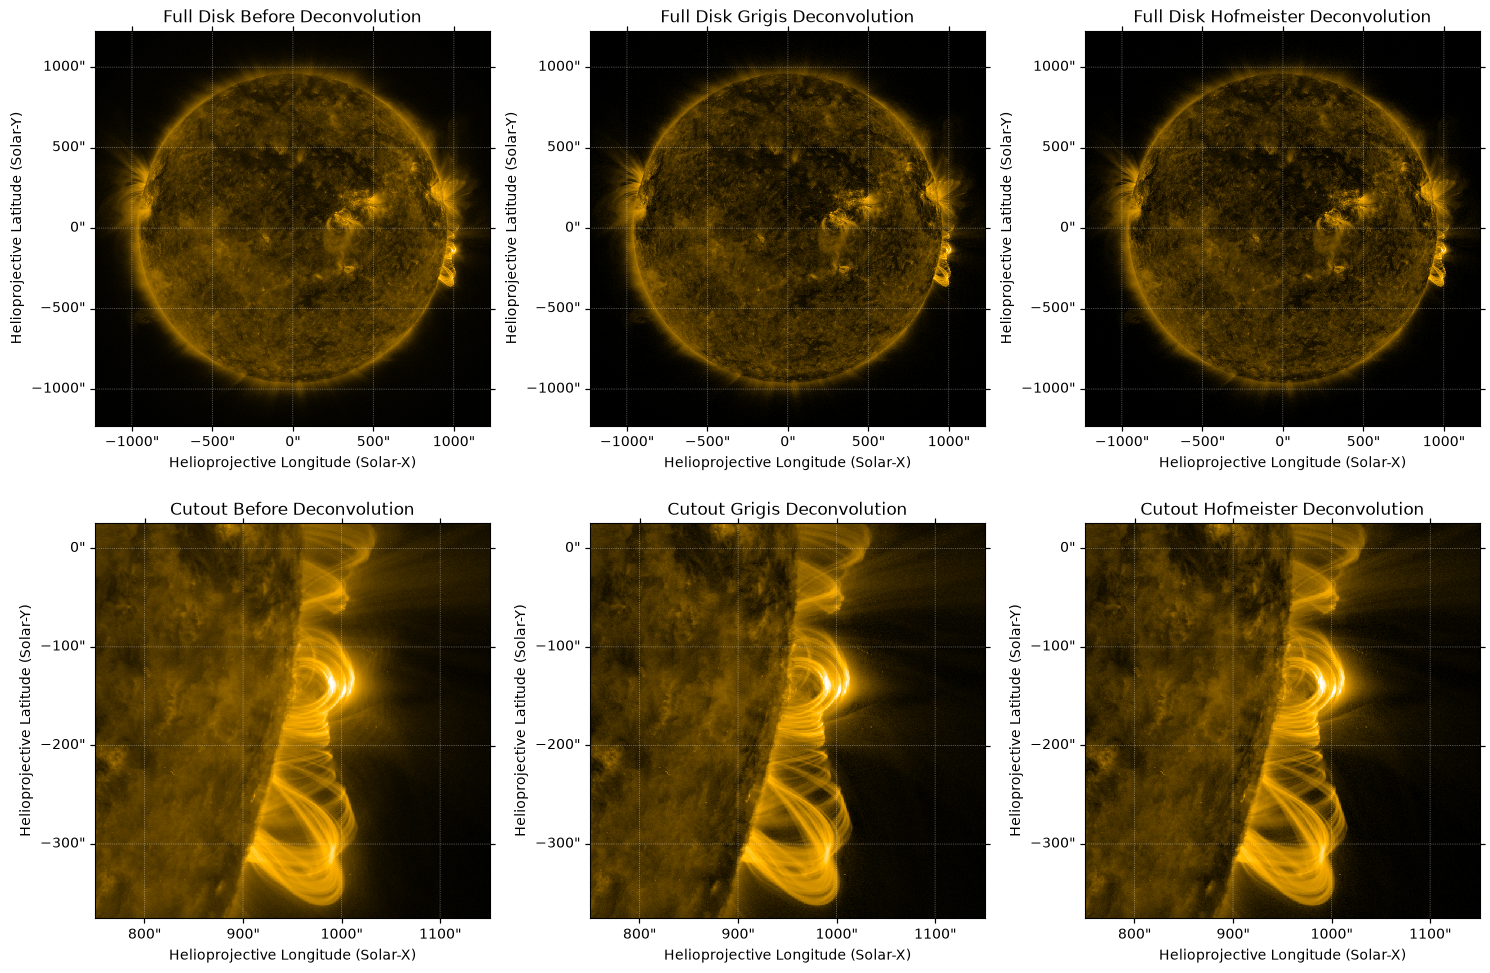

In [14]:
bottom_left = SkyCoord(750, -375, unit="arcsec", frame=aia_map.coordinate_frame)
fov = {"width": 400 * u.arcsec, "height": 400 * u.arcsec}

aia_map_sub = aia_map.submap(bottom_left, **fov)
deconv_grigis_sub = deconv_grigis.submap(bottom_left, **fov)
deconv_hofmeister_sub = deconv_hofmeister.submap(bottom_left, **fov)

fig = plt.figure(figsize=(15, 10))

# Row 1: Full Disk Images
# Original full disk
ax1 = fig.add_subplot(231, projection=aia_map)
aia_map.plot(axes=ax1, title="Full Disk Before Deconvolution")
# Grigis full disk
ax2 = fig.add_subplot(232, projection=deconv_grigis)
deconv_grigis.plot(axes=ax2, title="Full Disk Grigis Deconvolution")
# Hofmeister full disk
ax3 = fig.add_subplot(233, projection=deconv_hofmeister)
deconv_hofmeister.plot(axes=ax3, title="Full Disk Hofmeister Deconvolution")

# Row 2: Cutout Images
# Original cutout
ax4 = fig.add_subplot(234, projection=aia_map_sub)
aia_map_sub.plot(axes=ax4, title="Cutout Before Deconvolution")
# Grigis cutout
ax5 = fig.add_subplot(235, projection=deconv_grigis_sub)
deconv_grigis_sub.plot(axes=ax5, title="Cutout Grigis Deconvolution")
# Hofmeister cutout
ax6 = fig.add_subplot(236, projection=deconv_hofmeister_sub)
deconv_hofmeister_sub.plot(axes=ax6, title="Cutout Hofmeister Deconvolution")

fig.tight_layout()

## Total Irradiance Conservation

A PSF deconvolution should move flux around rather than create or destroy it, so for a PSF that only redistributes light the total DN in the frame should stay close to the original. Three things can change that total:

- **Clipping negatives.** The input has negative pixels. `aiapy` clips them to zero before deconvolving, which adds flux.
- **Boundary handling.**
    - `aiapy` uses periodic FFT boundaries, so light scattered past one edge wraps back into the frame and the sum is conserved. Its total should match the original apart from the clipping above, so the Grigis total should stay nearly the same.
    - The Hofmeister BID zero-pads to the full PSF size, so light scattered out of the frame is not returned to the output. The BID is designed to add back that out-of-field light, so its total is expected to rise above the original.
- **Positivity constraint.** The BID clips its deconvolved image to zero at every iteration, which adds flux. This is separate from the out-of-frame term; see "Reading the Hofmeister Numbers" below.

In [15]:
orig_total = np.sum(aia_map.data, dtype=np.float64)
totals = {
    "Original": aia_map.data,
    "Grigis (2012)": deconv_grigis.data,
    "Hofmeister (2025)": deconv_hofmeister.data,
}

print(f"{'Image':<20}{'Total DN':>16}{'% change':>12}{'Negative px':>14}{'NaN px':>10}")
for label, data in totals.items():
    total = np.sum(data, dtype=np.float64)
    pct = 100 * (total - orig_total) / orig_total
    print(
        f"{label:<20}{total:>16.6e}{pct:>+12.4f}"
        f"{np.sum(data < 0):>14}{np.sum(~np.isfinite(data)):>10}"
    )

Image                       Total DN    % change   Negative px    NaN px
Original                2.610050e+09     +0.0000        264793         0
Grigis (2012)           2.610392e+09     +0.0131             0         0
Hofmeister (2025)       2.753443e+09     +5.4939             0         0


In [16]:
# Sum the Negative Pixel DN in the original AIA image
negative_total = np.sum(aia_map.data[aia_map.data < 0], dtype=np.float64)
clip_added = -negative_total
print(
    f"Flux added by clipping negative input pixels: {clip_added:.6e} DN "
    f"({100 * clip_added / orig_total:+.4f}%)"
)

# Subtract the original total and the flux added by clipping from the Grigis total to see how much change is not explained by clipping.
grigis_total = np.sum(deconv_grigis.data, dtype=np.float64)
print(
    "Grigis change not explained by clipping: "
    f"{100 * (grigis_total - orig_total - clip_added) / orig_total:+.4f}%"
)

forward_hofmeister = convolve_image(
    img=deconv_hofmeister.data, psf=hofmeisters[171].data, large_psf=True
)
forward_total = np.sum(forward_hofmeister, dtype=np.float64)
hofmeister_total = np.sum(deconv_hofmeister.data, dtype=np.float64)
print(
    f"Hofmeister re-convolved, in-frame total: {forward_total:.6e} DN "
    f"({100 * (forward_total - orig_total) / orig_total:+.4f}% vs original)"
)
print(
    f"Scattered out of frame (model): {hofmeister_total - forward_total:.6e} DN "
    f"({100 * (hofmeister_total - forward_total) / orig_total:+.4f}% of original)"
)

Flux added by clipping negative input pixels: 3.421780e+05 DN (+0.0131%)
Grigis change not explained by clipping: +0.0000%
Hofmeister re-convolved, in-frame total: 2.615949e+09 DN (+0.2260% vs original)
Scattered out of frame (model): 1.374936e+08 DN (+5.2679% of original)


### Reading the Hofmeister Numbers

The BID's deconvolved image is cropped to the frame, so its total exceeds the original by the flux the PSF scatters out of the frame. Three quantities separate the contributions:

1. **Total change**: the sum of the deconvolved image compared with the original. This is the Hofmeister value in the table above.
2. **In-frame re-convolved change**: blur the deconvolved image with the same PSF and sum only the frame. The BID fits this to the observed frame, so it should be near 0%. A larger value means the positivity constraint is leaving a fit error.
3. **Scattered out of frame**: the difference between 1 and 2. This is the model's estimate of the light the PSF moves past the frame edge, and it is why the deconvolved image is brighter than the input.

Two other effects also change the total. The BID clips its deconvolved image to zero at every iteration (`constrain_positive=True`), which adds flux. Running it with `constrain_positive=False` fits the frame almost exactly and isolates the out-of-frame term, but it produces negative scene pixels, which are not physical. The difference between the two runs is the cost of the positivity constraint.

The out-of-frame term depends entirely on the PSF's wide wings, so it is only as reliable as the PSF.

In [17]:
deconv_hofmeister_free = deconvolve_bid(
    aia_map.data, hofmeisters[171].data, large_psf=True, constrain_positive=False
)


def hofmeister_budget(label, decon):
    forward = convolve_image(
        img=decon, psf=hofmeisters[171].data, large_psf=True
    ).astype(np.float64)
    decon_total = np.sum(decon, dtype=np.float64)
    forward_total = np.sum(forward, dtype=np.float64)
    print(label)
    print(
        "  Total change of deconvolved image:   "
        f"{100 * (decon_total - orig_total) / orig_total:+.4f}%"
    )
    print(
        "  In-frame re-convolved change:        "
        f"{100 * (forward_total - orig_total) / orig_total:+.4f}%"
    )
    print(
        "  Scattered out of frame (model):      "
        f"{100 * (decon_total - forward_total) / orig_total:+.4f}%"
    )
    print(
        "  Max |re-convolved - original|:       "
        f"{np.max(np.abs(forward - aia_map.data)):.2f} DN"
    )
    print(f"  Negative deconvolved pixels:         {np.sum(decon < 0)}")
    print()


hofmeister_budget(
    "Constrained (constrain_positive=True, used above):", deconv_hofmeister.data
)
hofmeister_budget("Unconstrained (constrain_positive=False):", deconv_hofmeister_free)

constrained_total = np.sum(deconv_hofmeister.data, dtype=np.float64)
unconstrained_total = np.sum(deconv_hofmeister_free, dtype=np.float64)
print(
    "Cost of positivity constraint: "
    f"{100 * (constrained_total - unconstrained_total) / orig_total:+.4f}%"
)

Constrained (constrain_positive=True, used above):
  Total change of deconvolved image:   +5.4939%
  In-frame re-convolved change:        +0.2260%
  Scattered out of frame (model):      +5.2679%
  Max |re-convolved - original|:       111.34 DN
  Negative deconvolved pixels:         0

Unconstrained (constrain_positive=False):
  Total change of deconvolved image:   +5.2476%
  In-frame re-convolved change:        +0.0000%
  Scattered out of frame (model):      +5.2476%
  Max |re-convolved - original|:       0.03 DN
  Negative deconvolved pixels:         2232319

Cost of positivity constraint: +0.2463%


### What the Hofmeister et al. (2025) Paper Says

The paper's section on applying the PSFs gives the reason for the out-of-frame term, "How to apply PSF deconvolutions"):

- Long-distance scattering is strong enough that "a portion of the light is scattered out of the field of view of the detectors," and this light "has to be retrieved to achieve correct results."
- Richardson-Lucy "conserves flux within the image, it cannot retrieve these photons and thus should not be used to deconvolve AIA images with our PSFs." The paper recommends the BID algorithm instead. The Grigis column above is therefore the one expected to conserve the total, and the Hofmeister column is not.
- Fourier-domain deconvolution implies periodic boundaries, so the image must be zero-padded by at least a quarter of the PSF edge length. For AIA this means an 8192 × 8192 padded image, which `large_psf=True` provides.
- For 171 Å, about 41% of the light is diffracted or scattered over the detector. Across channels, 3–10% is scattered farther than 1000 px. The 5.27% out-of-frame term is of the same order, but the paper does not give an out-of-frame fraction, so this is a consistency check rather than a validation.
- The paper calls the medium- to long-distance diffuse scatter the least certain part of the fit. Calibration artifacts of order 0.2 DN in lunar-occulted pixels affect the fit at that intensity level, so the out-of-frame term inherits that uncertainty.
- The paper does not discuss the positivity constraint. The +0.25% cost of `constrain_positive=True` comes from this BID implementation.

## Where the Negative Input Pixels Are

The negative values are in the L1 input itself, before any deconvolution. This plot marks them against the solar limb.

Negative pixels: 264793 (1.58% of frame), min -6 DN
Negative pixels on the solar disk: 0


Text(0, 0.5, 'Pixels')

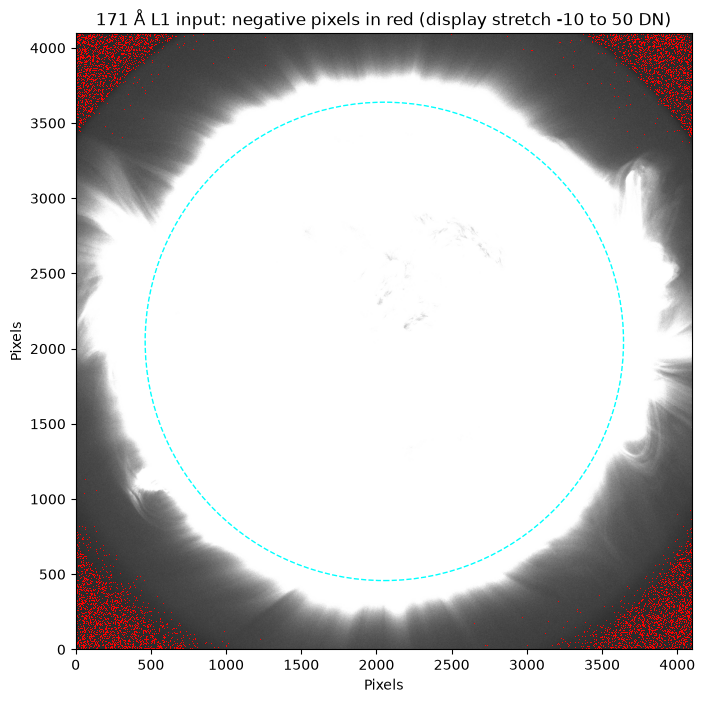

In [18]:
neg_mask = aia_map.data < 0
cx, cy = aia_map.reference_pixel.x.value, aia_map.reference_pixel.y.value
r_sun_px = aia_map.rsun_obs.value / aia_map.scale[0].value
yy, xx = np.indices(aia_map.data.shape)
on_disk = np.hypot(xx - cx, yy - cy) < r_sun_px

print(
    f"Negative pixels: {neg_mask.sum()} ({100 * neg_mask.mean():.2f}% of frame), "
    f"min {aia_map.data.min():.0f} DN"
)
print(f"Negative pixels on the solar disk: {(neg_mask & on_disk).sum()}")

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(aia_map.data, origin="lower", cmap="gray", vmin=-10, vmax=50)
ax.imshow(
    np.ma.masked_where(~neg_mask, neg_mask.astype(float)),
    origin="lower",
    cmap=colors.ListedColormap(["red"]),
    interpolation="nearest",
)
ax.add_patch(Circle((cx, cy), r_sun_px, fill=False, edgecolor="cyan", linestyle="--"))
ax.set_title("171 Å L1 input: negative pixels in red (display stretch -10 to 50 DN)")
ax.set_xlabel("Pixels")
ax.set_ylabel("Pixels")